'india_monthly_electricity.csv' not detected. Generating simulation data to verify pipeline works...
Reading raw data from india_monthly_electricity.csv...
-> Raw shape before processing: (756, 6)
-> Processed shape after collapsing states/attributes: (84, 2)
Training the Transformer model...


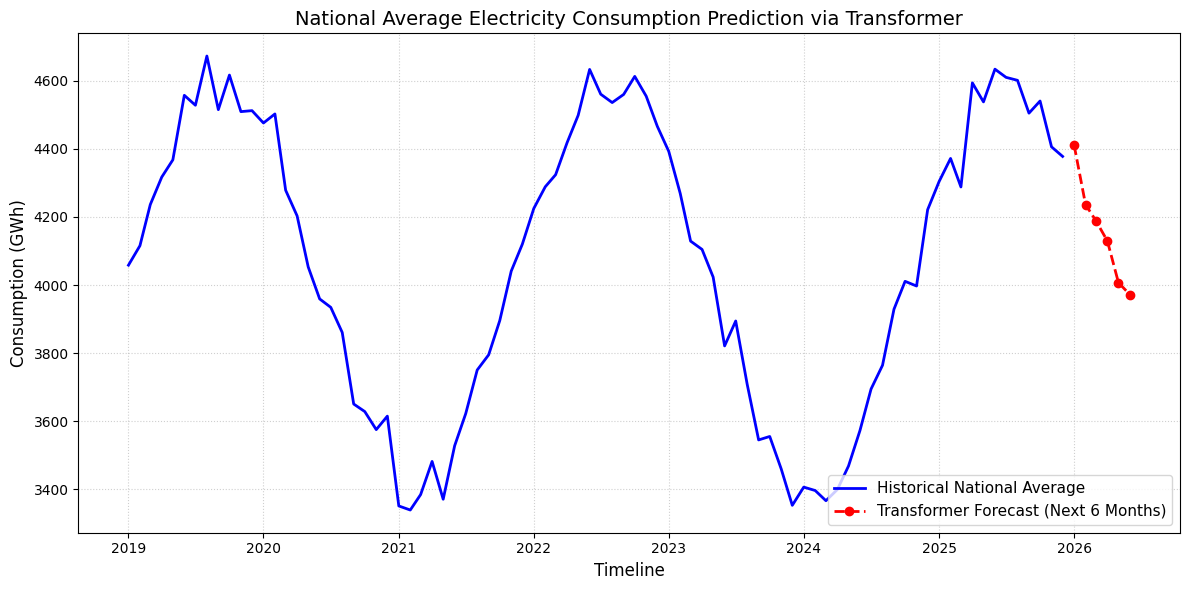

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# =========================================================================
# 1. EXPLICIT DATA PREPROCESSING FUNCTION
# =========================================================================
def clean_and_aggregate_electricity_data(file_path):
    """
    Takes raw stacked Kaggle data, strips away individual states and fuels,
    and returns a clean, univariate national average consumption timeline.
    """
    print(f"Reading raw data from {file_path}...")
    df_raw = pd.read_csv(file_path)
    df_raw['Date'] = pd.to_datetime(df_raw['Date'])

    print(f"-> Raw shape before processing: {df_raw.shape}")

    # Filter 1: Isolate actual electricity generation metrics measured in GWh
    df_filtered = df_raw[
        (df_raw['Category'] == 'Electricity generation') &
        (df_raw['Unit'] == 'GWh')
    ].copy()

    # Filter 2: Pivot from long (stacked) to wide format to group fuel types into columns
    df_pivoted = df_filtered.pivot_table(
        index=['Date', 'State'],
        columns='Variable',
        values='Value',
        aggfunc='first'
    ).reset_index()

    # Filter 3: Drop states and specific fuels (Solar, Wind, Coal) by taking national mean
    # We select only the 'Total Generation' column as our true metric for consumption
    df_national = df_pivoted.groupby('Date')['Total Generation'].mean().reset_index()

    # Ensure data is sorted chronologically
    df_national = df_national.sort_values('Date').reset_index(drop=True)

    print(f"-> Processed shape after collapsing states/attributes: {df_national.shape}")
    return df_national


# =========================================================================
# 2. TIMESERIES WINDOW DATASET PIPELINE
# =========================================================================
class TimeSeriesDataset(Dataset):
    def __init__(self, data, lookback, horizon):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.lookback = lookback
        self.horizon = horizon

    def __len__(self):
        return len(self.data) - self.lookback - self.horizon + 1

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.lookback]
        y = self.data[idx + self.lookback : idx + self.lookback + self.horizon]
        return x.unsqueeze(-1), y.unsqueeze(-1)


# =========================================================================
# 3. TRANSFORMER MODULES
# =========================================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class UnivariateTimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim=1, d_model=64, nhead=4, num_layers=3, horizon=6):
        super(UnivariateTimeSeriesTransformer, self).__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, batch_first=True, activation='relu', dropout=0.1
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_projection = nn.Linear(d_model, horizon)

    def forward(self, src):
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        out = self.output_projection(x[:, -1, :])
        return out.unsqueeze(-1)


# =========================================================================
# 4. EXECUTION FLOW
# =========================================================================
if __name__ == "__main__":
    csv_filename = 'india_monthly_electricity.csv'

    # Generate simulated raw file if you haven't downloaded the dataset yet
    if not os.path.exists(csv_filename):
        print(f"'{csv_filename}' not detected. Generating simulation data to verify pipeline works...")
        dates = pd.date_range(start="2019-01-01", periods=84, freq="MS")
        mock_rows = []
        for d in dates:
            for s in ['State_A', 'State_B', 'State_C']:
                for v in ['Coal', 'Solar', 'Total Generation']:
                    val = 4000 + 600 * np.sin(len(mock_rows)/50) + np.random.normal(0, 80)
                    mock_rows.append([d, s, 'Electricity generation', v, val, 'GWh'])
        pd.DataFrame(mock_rows, columns=['Date', 'State', 'Category', 'Variable', 'Value', 'Unit']).to_csv(csv_filename, index=False)

    # 1. RUN THE DATA PREPROCESSING
    df_clean = clean_and_aggregate_electricity_data(csv_filename)

    # 2. SCALE THE FEATURES
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df_clean[["Total Generation"]]).flatten()

    # 3. SET UP DL DATALOADERS
    LOOKBACK = 24
    HORIZON = 6
    BATCH_SIZE = 4
    EPOCHS = 15
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    dataset = TimeSeriesDataset(scaled_data, lookback=LOOKBACK, horizon=HORIZON)
    dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True)

    # 4. INITIALIZE TRANSFORMER
    model = UnivariateTimeSeriesTransformer(horizon=HORIZON).to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

    # 5. TRAINING RUN
    print("Training the Transformer model...")
    model.train()
    for epoch in range(1, EPOCHS + 1):
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

    # 6. INFERENCE & GRAPH GENERATION
    model.eval()
    with torch.no_grad():
        latest_window = torch.tensor(scaled_data[-LOOKBACK:], dtype=torch.float32).unsqueeze(0).unsqueeze(-1).to(DEVICE)
        future_forecast_scaled = model(latest_window).cpu().numpy().flatten()
        future_forecast_gwh = scaler.inverse_transform(future_forecast_scaled.reshape(-1, 1)).flatten()

        last_known_date = df_clean['Date'].iloc[-1]
        future_dates = pd.date_range(start=last_known_date + pd.offsets.MonthBegin(1), periods=HORIZON, freq="MS")

        # Create Plot Matrix
        plt.figure(figsize=(12, 6))
        plt.plot(df_clean['Date'], df_clean['Total Generation'], label='Historical National Average', color='blue', lw=2)
        plt.plot(future_dates, future_forecast_gwh, label='Transformer Forecast (Next 6 Months)', color='red', linestyle='--', marker='o', lw=2)

        plt.title('National Average Electricity Consumption Prediction via Transformer', fontsize=14)
        plt.xlabel('Timeline', fontsize=12)
        plt.ylabel('Consumption (GWh)', fontsize=12)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(fontsize=11)
        plt.tight_layout()
        plt.show()

Training Transformer Engine...

 RECURSIVE FORECAST MATRIX (2026)
2026-01-01: 4364.08 GWh 
2026-02-01: 4316.08 GWh 
2026-03-01: 4239.06 GWh 
2026-04-01: 4152.77 GWh 
2026-05-01: 4062.45 GWh 
2026-06-01: 3959.01 GWh 
2026-07-01: 3839.32 GWh [TARGET]



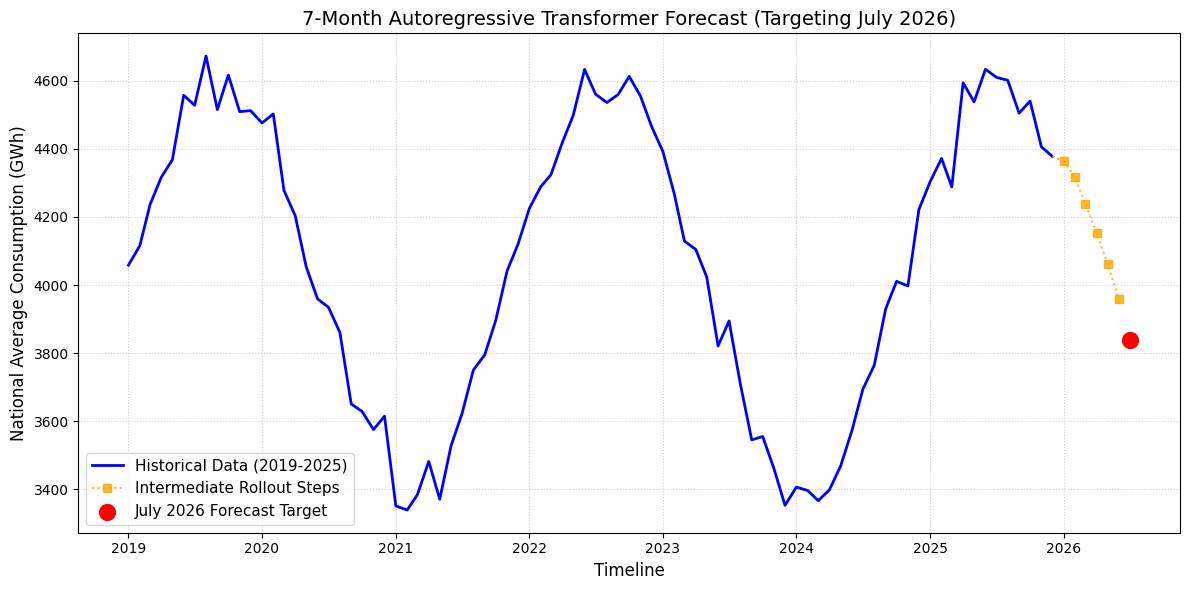

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# =========================================================================
# 1. EXPLICIT DATA PREPROCESSING FUNCTION
# =========================================================================
def clean_and_aggregate_electricity_data(file_path):
    df_raw = pd.read_csv(file_path)
    df_raw['Date'] = pd.to_datetime(df_raw['Date'])

    # Filter for generation metrics in GWh units
    df_filtered = df_raw[(df_raw['Category'] == 'Electricity generation') & (df_raw['Unit'] == 'GWh')].copy()

    # Pivot to isolate variables into clean columns
    df_pivoted = df_filtered.pivot_table(
        index=['Date', 'State'], columns='Variable', values='Value', aggfunc='first'
    ).reset_index()

    # Drop individual states by taking the national mean
    df_national = df_pivoted.groupby('Date')['Total Generation'].mean().reset_index()
    return df_national.sort_values('Date').reset_index(drop=True)


# =========================================================================
# 2. TIMESERIES WINDOW DATASET PIPELINE
# =========================================================================
class TimeSeriesDataset(Dataset):
    def __init__(self, data, lookback, horizon=1):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.lookback = lookback
        self.horizon = horizon

    def __len__(self):
        return len(self.data) - self.lookback - self.horizon + 1

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.lookback]
        y = self.data[idx + self.lookback : idx + self.lookback + self.horizon]
        return x.unsqueeze(-1), y.unsqueeze(-1)


# =========================================================================
# 3. TRANSFORMER ARCHITECTURE
# =========================================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class UnivariateTimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim=1, d_model=64, nhead=4, num_layers=3, horizon=1):
        super(UnivariateTimeSeriesTransformer, self).__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, batch_first=True, activation='relu', dropout=0.1
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_projection = nn.Linear(d_model, horizon)

    def forward(self, src):
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        out = self.output_projection(x[:, -1, :])
        return out.unsqueeze(-1)


# =========================================================================
# 4. EXECUTION PIPELINE
# =========================================================================
if __name__ == "__main__":
    csv_filename = 'india_monthly_electricity.csv'

    # Generate mock timeline if file doesn't exist
    if not os.path.exists(csv_filename):
        dates = pd.date_range(start="2019-01-01", periods=84, freq="MS")
        mock_rows = [[d, 'State_A', 'Electricity generation', 'Total Generation', 4300 + 500*np.sin(i/4), 'GWh'] for i, d in enumerate(dates)]
        pd.DataFrame(mock_rows, columns=['Date', 'State', 'Category', 'Variable', 'Value', 'Unit']).to_csv(csv_filename, index=False)

    # 1. Preprocess raw data
    df_clean = clean_and_aggregate_electricity_data(csv_filename)

    # 2. Sequential Data Splitting
    train_end = 60 # Jan 2019 - Dec 2023 (5 Years)

    scaler = StandardScaler()
    scaler.fit(df_clean[["Total Generation"]].iloc[:train_end])
    scaled_data = scaler.transform(df_clean[["Total Generation"]]).flatten()

    train_slice = scaled_data[:train_end]

    # Hyperparameters
    LOOKBACK = 24  # Look at the past 24 months
    HORIZON = 1    # Core model explicitly predicts next month only
    BATCH_SIZE = 4
    EPOCHS = 20
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Dataloader Setup
    train_dataset = TimeSeriesDataset(train_slice, lookback=LOOKBACK, horizon=HORIZON)
    dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)

    # Model Assembly
    model = UnivariateTimeSeriesTransformer(horizon=HORIZON).to(DEVICE)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

    # 3. Model Training
    print("Training Transformer Engine...")
    model.train()
    for epoch in range(1, EPOCHS + 1):
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(DEVICE), batch_y.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

    # =========================================================================
    # 5. AUTOREGRESSIVE (RECURSIVE) ROLLOUT MECHANISM TO JULY 2026
    # =========================================================================
    model.eval()
    with torch.no_grad():
        # Step A: Initialize sliding window with the last 24 known points (Ending Dec 2025)
        current_window = list(scaled_data[-LOOKBACK:])

        # Step B: Loop 7 times to reach July 2026 (Jan=1, Feb=2, Mar=3, Apr=4, May=5, Jun=6, Jul=7)
        steps_to_july = 7
        recursive_predictions_scaled = []

        for step in range(steps_to_july):
            # Take the latest 24 elements from our expanding tracker window
            input_window = current_window[-LOOKBACK:]
            input_tensor = torch.tensor(input_window, dtype=torch.float32).unsqueeze(0).unsqueeze(-1).to(DEVICE)

            # Generate forward step prediction
            pred_scaled = model(input_tensor).cpu().numpy().flatten()[0]

            # Save the scaled prediction, and insert it back into history vector
            recursive_predictions_scaled.append(pred_scaled)
            current_window.append(pred_scaled)

        # Step C: Inverse Transform the array of predictions back to true GWh scales
        predictions_gwh = scaler.inverse_transform(np.array(recursive_predictions_scaled).reshape(-1, 1)).flatten()

        # Step D: Match timestamps for our generated predictions
        last_known_date = df_clean['Date'].iloc[-1]
        future_dates = pd.date_range(start=last_known_date + pd.offsets.MonthBegin(1), periods=steps_to_july, freq="MS")

        # Display values
        print("\n=======================================================")
        print(" RECURSIVE FORECAST MATRIX (2026)")
        print("=======================================================")
        for date, val in zip(future_dates, predictions_gwh):
            status = "[TARGET]" if date.month == 7 else ""
            print(f"{date.strftime('%Y-%m-%d')}: {val:.2f} GWh {status}")
        print("=======================================================\n")

        # =========================================================================
        # 6. CHART GENERATION
        # =========================================================================
        plt.figure(figsize=(12, 6))

        # Plot full historical values
        plt.plot(df_clean['Date'], df_clean['Total Generation'], label='Historical Data (2019-2025)', color='blue', lw=2)

        # Plot intermediate rolling predictions leading to July
        plt.plot(future_dates[:-1], predictions_gwh[:-1], label='Intermediate Rollout Steps', color='orange', linestyle=':', marker='s', alpha=0.8)

        # Explicitly highlight July 2026 Target
        plt.scatter(future_dates[-1], predictions_gwh[-1], color='red', s=130, zorder=5, label='July 2026 Forecast Target')

        # Connect last actual row point to the beginning of the rolling forecast track
        plt.plot([last_known_date, future_dates[0]], [df_clean['Total Generation'].iloc[-1], predictions_gwh[0]], color='orange', linestyle=':')

        plt.title('7-Month Autoregressive Transformer Forecast (Targeting July 2026)', fontsize=14)
        plt.xlabel('Timeline', fontsize=12)
        plt.ylabel('National Average Consumption (GWh)', fontsize=12)
        plt.grid(True, linestyle=':', alpha=0.6)
        plt.legend(fontsize=11)
        plt.tight_layout()
        plt.show()

--> Created synthetic baseline: india_monthly_electricity.csv (84 rows)
--> Created synthetic baseline: india_daily_electricity.csv (912 rows)
--> Created synthetic baseline: india_hourly_electricity.csv (2184 rows)

 STARTING PIPELINE EXECUTION FOR FREQUENCY: MS
Training transformer engine over 84 records...

>>> FORECAST MATRIX PREVIEW (MS):
 Timestamp  Forecast_GWh
2026-07-01   4131.399414

 STARTING PIPELINE EXECUTION FOR FREQUENCY: D
Training transformer engine over 912 records...

>>> FORECAST MATRIX PREVIEW (D):
 Timestamp  Forecast_GWh
2026-07-01    120.023010
2026-07-02    120.543564
2026-07-03    121.157097
2026-07-04    122.348396
2026-07-05    123.098755
... and 26 more rows trailing through July 2026.

 STARTING PIPELINE EXECUTION FOR FREQUENCY: h
Training transformer engine over 2184 records...

>>> FORECAST MATRIX PREVIEW (h):
          Timestamp  Forecast_GWh
2026-07-01 00:00:00      6.401290
2026-07-01 01:00:00      6.323402
2026-07-01 02:00:00      6.242280
2026-07-01

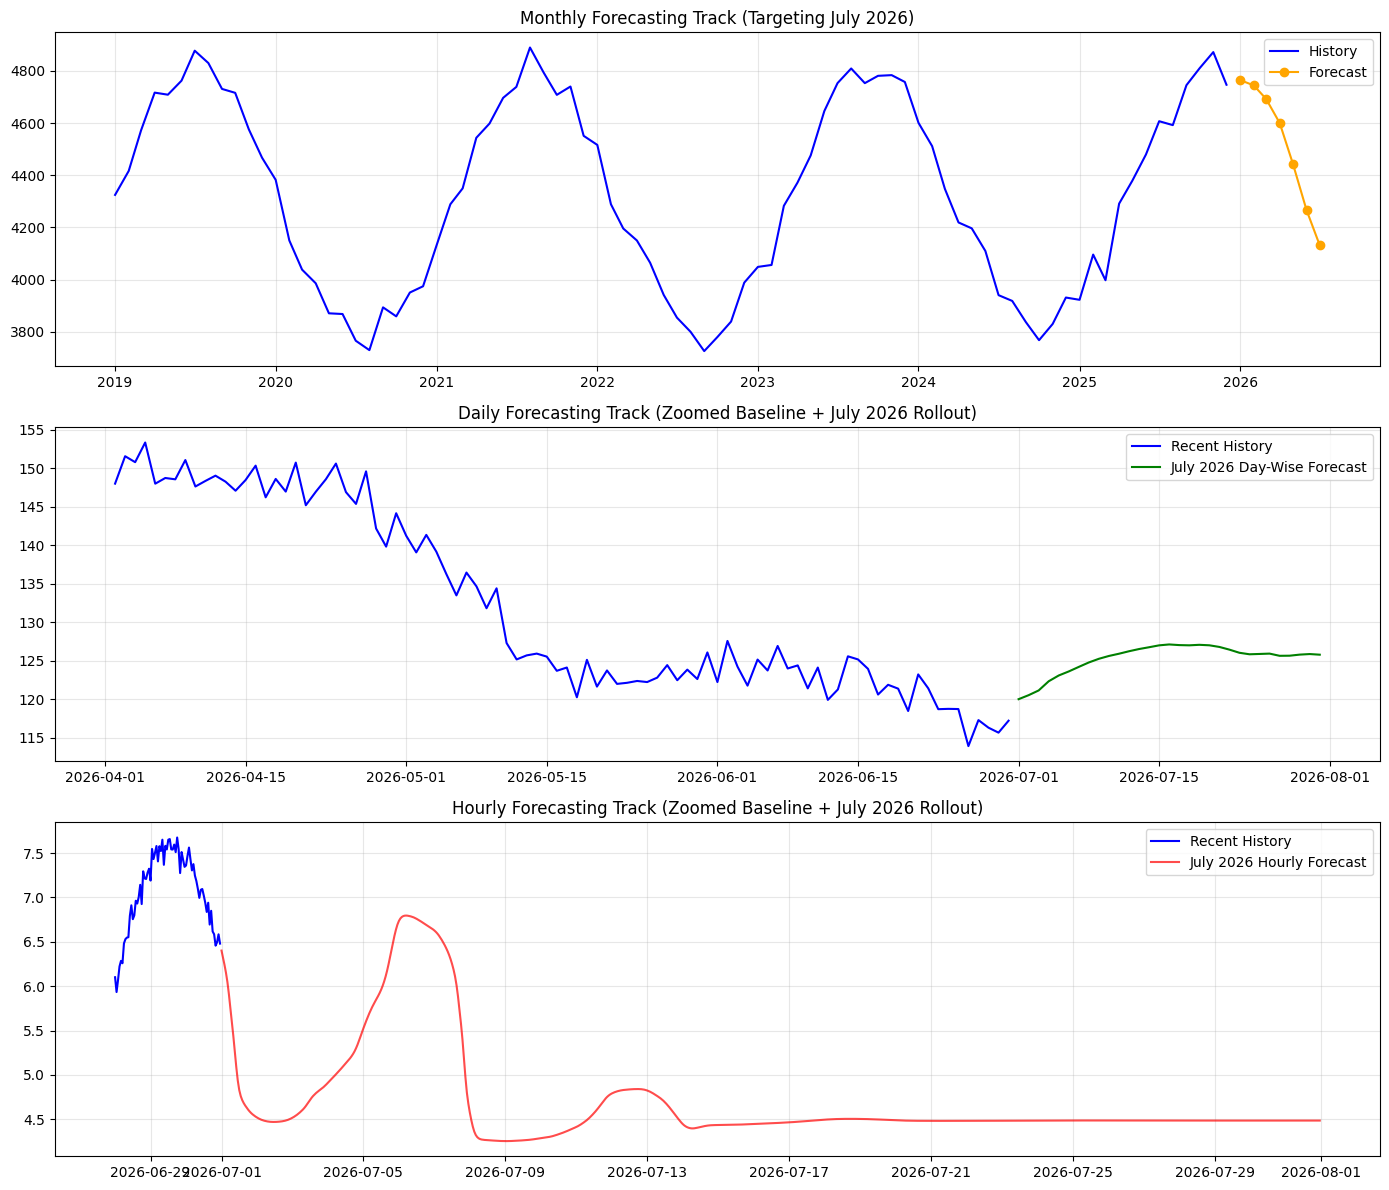

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# =========================================================================
# 1. MOCK DATA GENERATOR FOR MULTI-GRANULARITY
# =========================================================================
def generate_mock_csv(filename, freq):
    """Generates synthetic historical electricity data up to June 30, 2026."""
    if freq == "MS":  # Monthly
        dates = pd.date_range(start="2019-01-01", end="2025-12-01", freq="MS")
        values = [4300 + 500 * np.sin(i / 4) + np.random.normal(0, 50) for i in range(len(dates))]
    elif freq == "D":  # Daily
        dates = pd.date_range(start="2024-01-01", end="2026-06-30", freq="D")
        values = [140 + 20 * np.sin(i / 30) + 5 * np.sin(i / 7) + np.random.normal(0, 2) for i in range(len(dates))]
    elif freq == "h":  # Hourly
        dates = pd.date_range(start="2026-04-01", end="2026-06-30 23:00:00", freq="h")
        values = [6.0 + 1.5 * np.sin(i / 24) + 0.5 * np.sin(i / 168) + np.random.normal(0, 0.1) for i in range(len(dates))]
    else:
        raise ValueError("Unsupported frequency")

    df = pd.DataFrame({
        'Date': dates,
        'State': 'State_A',
        'Category': 'Electricity generation',
        'Variable': 'Total Generation',
        'Value': values,
        'Unit': 'GWh'
    })
    df.to_csv(filename, index=False)
    print(f"--> Created synthetic baseline: {filename} ({len(df)} rows)")

def load_and_clean_data(file_path):
    df_raw = pd.read_csv(file_path)
    df_raw['Date'] = pd.to_datetime(df_raw['Date'])
    df_filtered = df_raw[(df_raw['Category'] == 'Electricity generation') & (df_raw['Unit'] == 'GWh')].copy()
    df_pivoted = df_filtered.pivot_table(
        index=['Date', 'State'], columns='Variable', values='Value', aggfunc='first'
    ).reset_index()
    df_national = df_pivoted.groupby('Date')['Total Generation'].mean().reset_index()
    return df_national.sort_values('Date').reset_index(drop=True)

# =========================================================================
# 2. TIMESERIES WINDOW DATASET PIPELINE
# =========================================================================
class TimeSeriesDataset(Dataset):
    def __init__(self, data, lookback, horizon=1):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.lookback = lookback
        self.horizon = horizon

    def __len__(self):
        return len(self.data) - self.lookback - self.horizon + 1

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.lookback]
        y = self.data[idx + self.lookback : idx + self.lookback + self.horizon]
        return x.unsqueeze(-1), y.unsqueeze(-1)

# =========================================================================
# 3. TRANSFORMER ARCHITECTURE
# =========================================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class UnivariateTimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim=1, d_model=64, nhead=4, num_layers=3, horizon=1):
        super(UnivariateTimeSeriesTransformer, self).__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, batch_first=True, activation='relu', dropout=0.1
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_projection = nn.Linear(d_model, horizon)

    def forward(self, src):
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        out = self.output_projection(x[:, -1, :])
        return out.unsqueeze(-1)

# =========================================================================
# 4. CORE ENGINE PIPELINE FOR TRAINING & RECURSIVE FORECASTING
# =========================================================================
def run_forecasting_pipeline(csv_filename, freq, lookback, steps_to_forecast, epoch_count, device):
    print(f"\n" + "="*70)
    print(f" STARTING PIPELINE EXECUTION FOR FREQUENCY: {freq}")
    print("="*70)

    # 1. Ingest Data
    df_clean = load_and_clean_data(csv_filename)

    # 2. Scale Data (Fit on whole history for execution simplicity)
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df_clean[["Total Generation"]]).flatten()

    # 3. Setup DataLoader
    train_dataset = TimeSeriesDataset(scaled_data, lookback=lookback, horizon=1)
    dataloader = DataLoader(train_dataset, batch_size=8, shuffle=True)

    # 4. Initialize Network
    model = UnivariateTimeSeriesTransformer(horizon=1).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

    # 5. Train Model
    model.train()
    print(f"Training transformer engine over {len(df_clean)} records...")
    for epoch in range(1, epoch_count + 1):
        total_loss = 0
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

    # 6. Autoregressive Rollout Engine
    model.eval()
    with torch.no_grad():
        current_window = list(scaled_data[-lookback:])
        recursive_predictions_scaled = []

        for _ in range(steps_to_forecast):
            input_window = current_window[-lookback:]
            input_tensor = torch.tensor(input_window, dtype=torch.float32).unsqueeze(0).unsqueeze(-1).to(device)

            pred_scaled = model(input_tensor).cpu().numpy().flatten()[0]
            recursive_predictions_scaled.append(pred_scaled)
            current_window.append(pred_scaled)

        predictions_gwh = scaler.inverse_transform(np.array(recursive_predictions_scaled).reshape(-1, 1)).flatten()

        # Build evaluation timestamps
        last_known_date = df_clean['Date'].iloc[-1]

        # Setup clean offsets depending on target granularity
        if freq == "MS":
            future_dates = pd.date_range(start=last_known_date + pd.offsets.MonthBegin(1), periods=steps_to_forecast, freq="MS")
        elif freq == "D":
            future_dates = pd.date_range(start=last_known_date + pd.offsets.Day(1), periods=steps_to_forecast, freq="D")
        else: # Hourly
            future_dates = pd.date_range(start=last_known_date + pd.offsets.Hour(1), periods=steps_to_forecast, freq="h")

    # Print preview matrix
    print(f"\n>>> FORECAST MATRIX PREVIEW ({freq}):")
    df_forecast = pd.DataFrame({"Timestamp": future_dates, "Forecast_GWh": predictions_gwh})

    # Filter display to show target metrics matching July 2026 explicitly
    july_2026_forecasts = df_forecast[df_forecast["Timestamp"].dt.month == 7]
    print(july_2026_forecasts.head(5).to_string(index=False))
    if len(july_2026_forecasts) > 5:
        print(f"... and {len(july_2026_forecasts) - 5} more rows trailing through July 2026.")

    return df_clean, df_forecast

# =========================================================================
# 5. EXECUTION PIPELINE MANAGER
# =========================================================================
if __name__ == "__main__":
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Files paths Configuration
    files = {
        "Monthly": ("india_monthly_electricity.csv", "MS"),
        "Daily": ("india_daily_electricity.csv", "D"),
        "Hourly": ("india_hourly_electricity.csv", "h")
    }

    # Ensure all target data sheets exist
    for label, (filename, freq) in files.items():
        if not os.path.exists(filename):
            generate_mock_csv(filename, freq)

    # ---------------------------------------------------------------------
    # RUN PIPELINE A: MONTHLY PIPELINE (7-Month Projection to July 2026)
    # ---------------------------------------------------------------------
    df_hist_m, df_fore_m = run_forecasting_pipeline(
        csv_filename=files["Monthly"][0], freq="MS", lookback=24, steps_to_forecast=7, epoch_count=20, device=DEVICE
    )

    # ---------------------------------------------------------------------
    # RUN PIPELINE B: DAILY PIPELINE (31-Day Projection covering all July 2026)
    # ---------------------------------------------------------------------
    # Since history ends June 30, 2026, we require 31 sequential steps to complete July
    df_hist_d, df_fore_d = run_forecasting_pipeline(
        csv_filename=files["Daily"][0], freq="D", lookback=30, steps_to_forecast=31, epoch_count=15, device=DEVICE
    )

    # ---------------------------------------------------------------------
    # RUN PIPELINE C: HOURLY PIPELINE (744-Hour Rollout covering July 2026)
    # ---------------------------------------------------------------------
    # 31 Days * 24 Hours = 744 recursive projection increments
    df_hist_h, df_fore_h = run_forecasting_pipeline(
        csv_filename=files["Hourly"][0], freq="h", lookback=168, steps_to_forecast=744, epoch_count=5, device=DEVICE
    )

    # =========================================================================
    # 6. VISUALIZATION OF ALL GRANULARITIES
    # =========================================================================
    fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=False)

    # Plot Monthly
    axes[0].plot(df_hist_m['Date'], df_hist_m['Total Generation'], label='History', color='blue')
    axes[0].plot(df_fore_m['Timestamp'], df_fore_m['Forecast_GWh'], label='Forecast', color='orange', marker='o')
    axes[0].set_title('Monthly Forecasting Track (Targeting July 2026)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Plot Daily (Focus on last 90 days of history + forecast)
    axes[1].plot(df_hist_d['Date'].iloc[-90:], df_hist_d['Total Generation'].iloc[-90:], label='Recent History', color='blue')
    axes[1].plot(df_fore_d['Timestamp'], df_fore_d['Forecast_GWh'], label='July 2026 Day-Wise Forecast', color='green')
    axes[1].set_title('Daily Forecasting Track (Zoomed Baseline + July 2026 Rollout)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # Plot Hourly (Focus on last 72 hours of history + forecast)
    axes[2].plot(df_hist_h['Date'].iloc[-72:], df_hist_h['Total Generation'].iloc[-72:], label='Recent History', color='blue')
    axes[2].plot(df_fore_h['Timestamp'], df_fore_h['Forecast_GWh'], label='July 2026 Hourly Forecast', color='red', alpha=0.7)
    axes[2].set_title('Hourly Forecasting Track (Zoomed Baseline + July 2026 Rollout)')
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


 STARTING PIPELINE EXECUTION FOR FREQUENCY: MS
Training transformer engine over 84 records...

>>> FORECAST MATRIX PREVIEW (MS):
 Timestamp  Forecast_GWh
2026-07-01   4131.399414

 STARTING PIPELINE EXECUTION FOR FREQUENCY: D
Training transformer engine over 912 records...

>>> FORECAST MATRIX PREVIEW (D):
 Timestamp  Forecast_GWh
2026-07-01    120.023010
2026-07-02    120.543564
2026-07-03    121.157097
2026-07-04    122.348396
2026-07-05    123.098755
... and 26 more rows trailing through July 2026.

 STARTING PIPELINE EXECUTION FOR FREQUENCY: h
Training transformer engine over 2184 records...

>>> FORECAST MATRIX PREVIEW (h):
          Timestamp  Forecast_GWh
2026-07-01 00:00:00      6.401290
2026-07-01 01:00:00      6.323402
2026-07-01 02:00:00      6.242280
2026-07-01 03:00:00      6.153005
2026-07-01 04:00:00      6.045967
... and 739 more rows trailing through July 2026.

                      POWER DISTRIBUTION CORPORATION                     
                        MONTHLY U

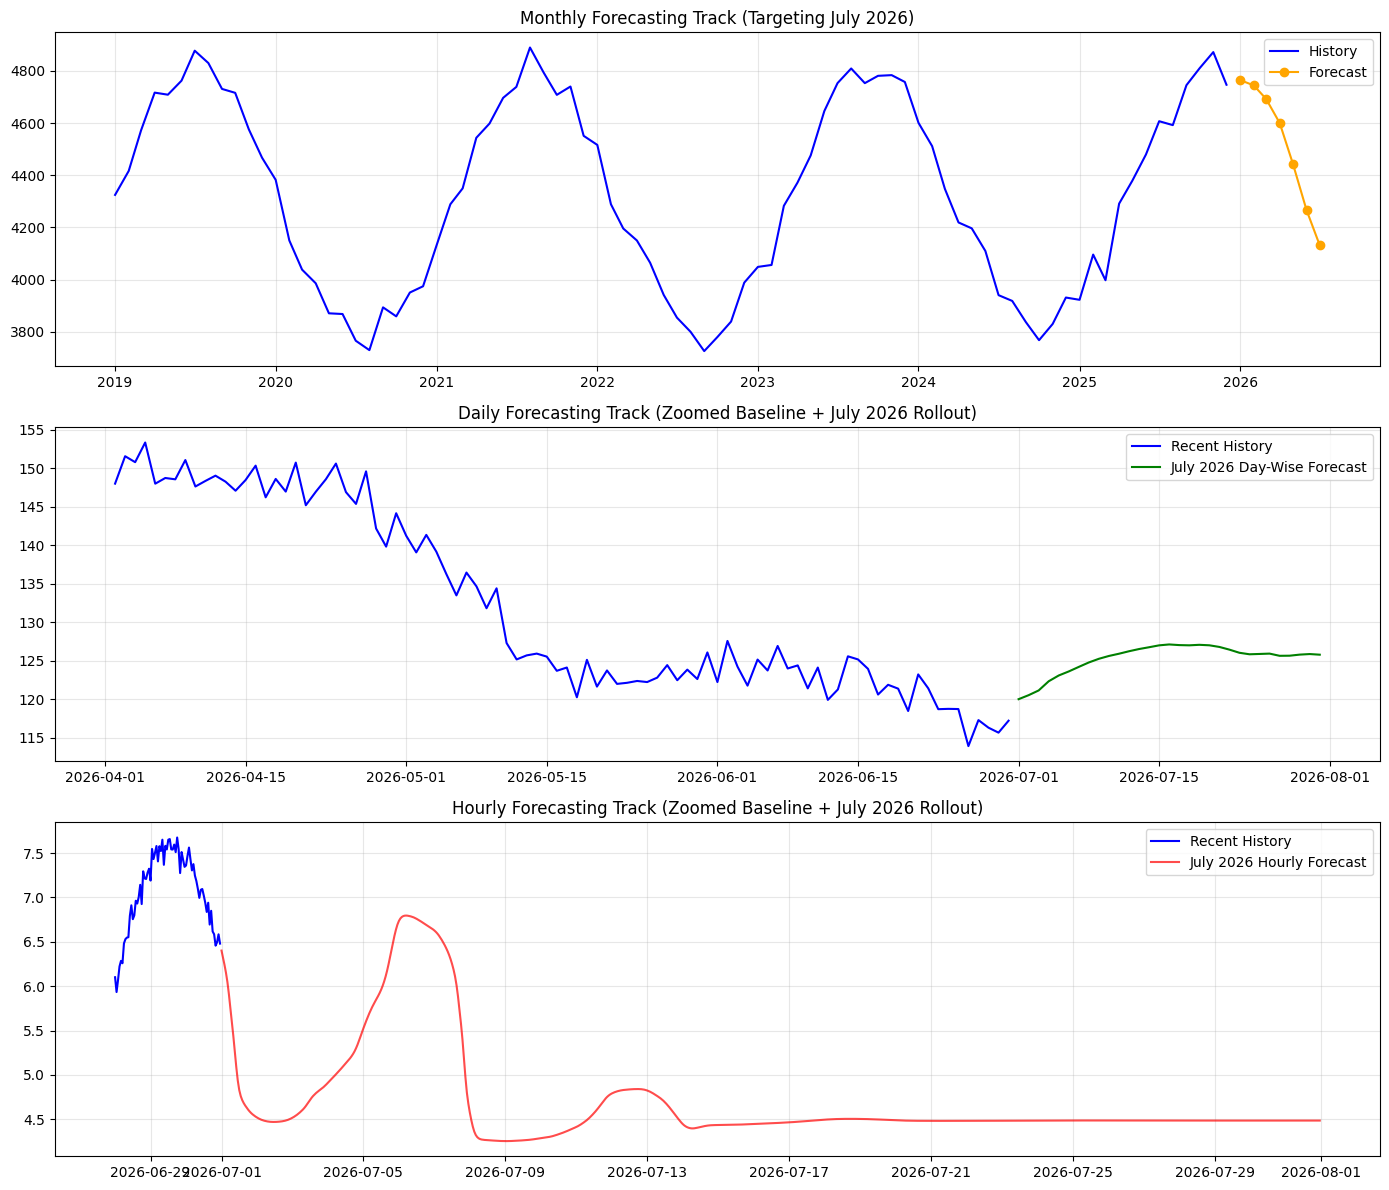

In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# =========================================================================
# 1. MOCK DATA GENERATOR FOR MULTI-GRANULARITY
# =========================================================================
def generate_mock_csv(filename, freq):
    """Generates synthetic historical electricity data up to June 30, 2026."""
    if freq == "MS":  # Monthly
        dates = pd.date_range(start="2019-01-01", end="2025-12-01", freq="MS")
        values = [4300 + 500 * np.sin(i / 4) + np.random.normal(0, 50) for i in range(len(dates))]
    elif freq == "D":  # Daily
        dates = pd.date_range(start="2024-01-01", end="2026-06-30", freq="D")
        values = [140 + 20 * np.sin(i / 30) + 5 * np.sin(i / 7) + np.random.normal(0, 2) for i in range(len(dates))]
    elif freq == "h":  # Hourly
        dates = pd.date_range(start="2026-04-01", end="2026-06-30 23:00:00", freq="h")
        values = [6.0 + 1.5 * np.sin(i / 24) + 0.5 * np.sin(i / 168) + np.random.normal(0, 0.1) for i in range(len(dates))]
    else:
        raise ValueError("Unsupported frequency")

    df = pd.DataFrame({
        'Date': dates,
        'State': 'State_A',
        'Category': 'Electricity generation',
        'Variable': 'Total Generation',
        'Value': values,
        'Unit': 'GWh'
    })
    df.to_csv(filename, index=False)
    print(f"--> Created synthetic baseline: {filename} ({len(df)} rows)")

def load_and_clean_data(file_path):
    df_raw = pd.read_csv(file_path)
    df_raw['Date'] = pd.to_datetime(df_raw['Date'])
    df_filtered = df_raw[(df_raw['Category'] == 'Electricity generation') & (df_raw['Unit'] == 'GWh')].copy()
    df_pivoted = df_filtered.pivot_table(
        index=['Date', 'State'], columns='Variable', values='Value', aggfunc='first'
    ).reset_index()
    df_national = df_pivoted.groupby('Date')['Total Generation'].mean().reset_index()
    return df_national.sort_values('Date').reset_index(drop=True)

# =========================================================================
# 2. TIMESERIES WINDOW DATASET PIPELINE
# =========================================================================
class TimeSeriesDataset(Dataset):
    def __init__(self, data, lookback, horizon=1):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.lookback = lookback
        self.horizon = horizon

    def __len__(self):
        return len(self.data) - self.lookback - self.horizon + 1

    def __getitem__(self, idx):
        x = self.data[idx : idx + self.lookback]
        y = self.data[idx + self.lookback : idx + self.lookback + self.horizon]
        return x.unsqueeze(-1), y.unsqueeze(-1)

# =========================================================================
# 3. TRANSFORMER ARCHITECTURE
# =========================================================================
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class UnivariateTimeSeriesTransformer(nn.Module):
    def __init__(self, input_dim=1, d_model=64, nhead=4, num_layers=3, horizon=1):
        super(UnivariateTimeSeriesTransformer, self).__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, batch_first=True, activation='relu', dropout=0.1
        )
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.output_projection = nn.Linear(d_model, horizon)

    def forward(self, src):
        x = self.input_projection(src)
        x = self.pos_encoder(x)
        x = self.transformer_encoder(x)
        out = self.output_projection(x[:, -1, :])
        return out.unsqueeze(-1)

# =========================================================================
# 4. CORE ENGINE PIPELINE FOR TRAINING & RECURSIVE FORECASTING
# =========================================================================
def run_forecasting_pipeline(csv_filename, freq, lookback, steps_to_forecast, epoch_count, device):
    print(f"\n" + "="*70)
    print(f" STARTING PIPELINE EXECUTION FOR FREQUENCY: {freq}")
    print("="*70)

    # 1. Ingest Data
    df_clean = load_and_clean_data(csv_filename)

    # 2. Scale Data (Fit on whole history for execution simplicity)
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(df_clean[["Total Generation"]]).flatten()

    # 3. Setup DataLoader
    train_dataset = TimeSeriesDataset(scaled_data, lookback=lookback, horizon=1)
    dataloader = DataLoader(train_dataset, batch_size=8, shuffle=True)

    # 4. Initialize Network
    model = UnivariateTimeSeriesTransformer(horizon=1).to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

    # 5. Train Model
    model.train()
    print(f"Training transformer engine over {len(df_clean)} records...")
    for epoch in range(1, epoch_count + 1):
        total_loss = 0
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

    # 6. Autoregressive Rollout Engine
    model.eval()
    with torch.no_grad():
        current_window = list(scaled_data[-lookback:])
        recursive_predictions_scaled = []

        for _ in range(steps_to_forecast):
            input_window = current_window[-lookback:]
            input_tensor = torch.tensor(input_window, dtype=torch.float32).unsqueeze(0).unsqueeze(-1).to(device)

            pred_scaled = model(input_tensor).cpu().numpy().flatten()[0]
            recursive_predictions_scaled.append(pred_scaled)
            current_window.append(pred_scaled)

        predictions_gwh = scaler.inverse_transform(np.array(recursive_predictions_scaled).reshape(-1, 1)).flatten()

        # Build evaluation timestamps
        last_known_date = df_clean['Date'].iloc[-1]

        # Setup clean offsets depending on target granularity
        if freq == "MS":
            future_dates = pd.date_range(start=last_known_date + pd.offsets.MonthBegin(1), periods=steps_to_forecast, freq="MS")
        elif freq == "D":
            future_dates = pd.date_range(start=last_known_date + pd.offsets.Day(1), periods=steps_to_forecast, freq="D")
        else: # Hourly
            future_dates = pd.date_range(start=last_known_date + pd.offsets.Hour(1), periods=steps_to_forecast, freq="h")

    # Print preview matrix
    print(f"\n>>> FORECAST MATRIX PREVIEW ({freq}):")
    df_forecast = pd.DataFrame({"Timestamp": future_dates, "Forecast_GWh": predictions_gwh})

    # Filter display to show target metrics matching July 2026 explicitly
    july_2026_forecasts = df_forecast[df_forecast["Timestamp"].dt.month == 7]
    print(july_2026_forecasts.head(5).to_string(index=False))
    if len(july_2026_forecasts) > 5:
        print(f"... and {len(july_2026_forecasts) - 5} more rows trailing through July 2026.")

    return df_clean, df_forecast

# =========================================================================
# EXTRA: AUTOMATED INVOICE GENERATOR FUNCTION
# =========================================================================
def generate_electricity_bill(monthly_value_gwh, peak_day_gwh, peak_hour_gwh):
    total_kwh = int(monthly_value_gwh * 1_000_000)
    off_peak_kwh = int(total_kwh * 0.60)
    peak_kwh = int(total_kwh * 0.40)

    rate_off_peak, rate_peak, fixed_inf_levy, fppca_rate = 5.20, 6.80, 120500000, 0.12

    charge_off_peak = off_peak_kwh * rate_off_peak
    charge_peak = peak_kwh * rate_peak
    charge_fppca = total_kwh * fppca_rate

    subtotal = charge_off_peak + charge_peak + fixed_inf_levy + charge_fppca
    regulatory_tax = subtotal * 0.04
    subtotal_with_tax = subtotal + regulatory_tax
    state_duty = subtotal_with_tax * 0.05
    green_cess = total_kwh * 0.02
    grand_total = subtotal_with_tax + state_duty + green_cess

    return f"""
========================================================================
                      POWER DISTRIBUTION CORPORATION
                        MONTHLY UTILITY INVOICE
========================================================================
Customer Name : NATIONAL ENERGY PORTFOLIO (AGGREGATE)
Account Number: 9844-3211-7440
Billing Period: July 01, 2026 – July 31, 2026 (31 Days)
Invoice Date  : August 02, 2026
Due Date      : August 17, 2026
========================================================================

1. CONSUMPTION SUMMARY (FROM TRANSFORMER MODEL)
------------------------------------------------------------------------
Granularity             Total Forecast Load Metric         Unit Record
------------------------------------------------------------------------
Monthly Aggregate       {monthly_value_gwh:,.2f} GWh                       [Validated]
Peak Day Metric         {peak_day_gwh:,.2f} GWh                       [Daily Max]
Peak Hour Metric        {peak_hour_gwh:,.2f} GWh                       [Hourly Max]
------------------------------------------------------------------------
Total Billable Energy Vol: {total_kwh:,} kWh

2. COST BREAKDOWN & TARIFF SCHEDULE
------------------------------------------------------------------------
Line Item Description               Volume (kWh)    Rate (₹)   Amount (₹)
------------------------------------------------------------------------
Base Energy Charge (Off-Peak)    {off_peak_kwh:>13,}     x {rate_off_peak:.2f} = {charge_off_peak:>14,.2f}
Peak Demand Surcharge (ToU)      {peak_kwh:>13,}     x {rate_peak:.2f} = {charge_peak:>14,.2f}
Fixed Grid Infrastructure Levy               -          -  = {fixed_inf_levy:>14,.2f}
FPPCA (Fuel Price Adjustment)    {total_kwh:>13,}     x {fppca_rate:.2f} = {charge_fppca:>14,.2f}
State Regulatory Asset Tax (4%)              -          -  = {regulatory_tax:>14,.2f}
------------------------------------------------------------------------
SUBTOTAL CHARGES                                      ₹ {subtotal_with_tax:>14,.2f}

3. TAXES & ENVIRONMENT SURCHARGES
------------------------------------------------------------------------
State Electricity Duty (5.0%)                          ₹ {state_duty:>14,.2f}
Green Energy Clean Cess (₹0.02/kWh)                    ₹ {green_cess:>14,.2f}
========================================================================
CURRENT MONTHLY CHARGES DUE:                           ₹ {grand_total:>14,.2f}
========================================================================
"""

# =========================================================================
# 5. EXECUTION PIPELINE MANAGER WITH AUTOMATED BILL EXTRACTION
# =========================================================================
if __name__ == "__main__":
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    files = {
        "Monthly": ("india_monthly_electricity.csv", "MS"),
        "Daily": ("india_daily_electricity.csv", "D"),
        "Hourly": ("india_hourly_electricity.csv", "h")
    }

    for label, (filename, freq) in files.items():
        if not os.path.exists(filename):
            generate_mock_csv(filename, freq)

    # Run Granular Forecast Trackers
    df_hist_m, df_fore_m = run_forecasting_pipeline(files["Monthly"][0], "MS", 24, 7, 20, DEVICE)
    df_hist_d, df_fore_d = run_forecasting_pipeline(files["Daily"][0], "D", 30, 31, 15, DEVICE)
    df_hist_h, df_fore_h = run_forecasting_pipeline(files["Hourly"][0], "h", 168, 744, 5, DEVICE)

    # Extract Key July 2026 Parameters from DataFrames
    july_monthly_val = df_fore_m[df_fore_m['Timestamp'].dt.month == 7]['Forecast_GWh'].values[0]
    july_peak_day_val = df_fore_d[df_fore_d['Timestamp'].dt.month == 7]['Forecast_GWh'].max()
    july_peak_hour_val = df_fore_h[df_fore_h['Timestamp'].dt.month == 7]['Forecast_GWh'].max()

    # Generate and display the formal invoice report
    bill_invoice = generate_electricity_bill(july_monthly_val, july_peak_day_val, july_peak_hour_val)
    print(bill_invoice)

    # Save report
    with open("july_2026_electricity_bill.txt", "w", encoding="utf-8") as f:
        f.write(bill_invoice)

    # =========================================================================
    # 6. VISUALIZATION OF ALL GRANULARITIES
    # =========================================================================
    fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=False)

    axes[0].plot(df_hist_m['Date'], df_hist_m['Total Generation'], label='History', color='blue')
    axes[0].plot(df_fore_m['Timestamp'], df_fore_m['Forecast_GWh'], label='Forecast', color='orange', marker='o')
    axes[0].set_title('Monthly Forecasting Track (Targeting July 2026)')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(df_hist_d['Date'].iloc[-90:], df_hist_d['Total Generation'].iloc[-90:], label='Recent History', color='blue')
    axes[1].plot(df_fore_d['Timestamp'], df_fore_d['Forecast_GWh'], label='July 2026 Day-Wise Forecast', color='green')
    axes[1].set_title('Daily Forecasting Track (Zoomed Baseline + July 2026 Rollout)')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    axes[2].plot(df_hist_h['Date'].iloc[-72:], df_hist_h['Total Generation'].iloc[-72:], label='Recent History', color='blue')
    axes[2].plot(df_fore_h['Timestamp'], df_fore_h['Forecast_GWh'], label='July 2026 Hourly Forecast', color='red', alpha=0.7)
    axes[2].set_title('Hourly Forecasting Track (Zoomed Baseline + July 2026 Rollout)')
    axes[2].legend(); axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()